In [3]:
#@title Importations

import matplotlib.pyplot as plt
from sortedcontainers import SortedSet


In [ ]:
#@title ABF

class NoeudBinaire:

    def __init__(self, element, gauche=None, droite=None):
        self._element = element
        self._gauche = gauche
        self._droite = droite

    def get_element(self):
        return self._element

    def set_element(self, element):
        self._element = element

    def get_gauche(self):
        return self._gauche

    def set_gauche(self, noeud) -> None:
        self._gauche = noeud

    def get_droite(self):
        return self._droite

    def set_droite(self, noeud) -> None:
        self._droite = noeud

    def get_degre(self) -> int:
        nb_fils = 0
        if self._gauche:
            nb_fils += 1
        if self._droite:
            nb_fils += 1
        return nb_fils

class ABF:
    def __init__(self):
        self._racine = None
        self._taille = 0

    # Pour exercice 7.3
    def __iter__(self):
        yield from self._parcours_infixe(self._racine)

    def _parcours_infixe(self, noeud:NoeudBinaire):
        if noeud != None:
            yield from self._parcours_infixe(noeud.get_gauche())
            yield noeud.get_element()
            yield from self._parcours_infixe(noeud.get_droite())

    def get_racine(self) -> NoeudBinaire:
        return self._racine

    # Pour exercice 7.1
    def inserer(self, valeur) -> None:
        nouveau_noeud = NoeudBinaire(valeur)
        if self._racine == None:
            self._racine = nouveau_noeud
        else:
            courant = self._racine
            place = False
            while not place:
                if valeur < courant.get_element():
                    if courant.get_gauche() == None:
                        courant.set_gauche(nouveau_noeud)
                        place = True
                    else:
                        courant = courant.get_gauche()
                else:
                    if courant.get_droite() == None:
                        courant.set_droite(nouveau_noeud)
                        place = True
                    else:
                        courant = courant.get_droite()
        self._taille += 1

    # Pour exercice 7.2
    def inserer_recursif(self, valeur) -> None:
        def _inserer(noeud:NoeudBinaire) -> NoeudBinaire:
            if noeud != None:
                if valeur < noeud.get_element():
                    noeud.set_gauche(_inserer(noeud.get_gauche()))
                else:
                    noeud.set_droite(_inserer(noeud.get_droite()))
            else:
                noeud = NoeudBinaire(valeur)
            return noeud
        self._racine = _inserer(self._racine)
        self._taille += 1

    # Pour exercice 7.4
    def __contains__(self, element):
        noeud = self._racine
        while noeud != None:
            if element == noeud.get_element():
                return True
            elif element < noeud.get_element():
                noeud = noeud.get_gauche()
            else:
                noeud = noeud.get_droite()
        return False

    # Pour exercice 7.5
    def supprimer(self, element):

        # Retourne la valeur du successeur
        def _successeur(noeud:NoeudBinaire):
            noeud = noeud.get_droite()
            while noeud.get_gauche() != None:
                noeud = noeud.get_gauche()
            return noeud.get_element()

        # Retire valeur du sous-arbre et retourne la nouvelle racine de ce sous-arbre
        def _suppression(noeud:NoeudBinaire, valeur) -> NoeudBinaire:
            if noeud != None:
                if valeur < noeud.get_element():
                    noeud.set_gauche(_suppression(noeud.get_gauche(), valeur))
                elif valeur > noeud.get_element():
                    noeud.set_droite(_suppression(noeud.get_droite(), valeur))
                # Ici, on a trouvé le noeud
                elif noeud.get_degre() == 2:
                    successeur = _successeur(noeud)
                    noeud.set_element(successeur)
                    # On supprime le prédécesseur
                    noeud.set_droite(_suppression(noeud.get_droite(), successeur))
                elif noeud.get_gauche() != None:
                    noeud = noeud.get_gauche()
                else:
                    noeud = noeud.get_droite()      # None si c'est une feuille
            return noeud

        if element in self:     # Si l'élément est absent, on ne fait rien
            self._racine = _suppression(self._racine, element)   # Si le noeud supprimé est la racine, il faut une nouvelle racine.
            self._taille -= 1

    # Pour exercice 7.7
    def equilibrer(self) -> None:

        def _reconstruire(debut:int, fin:int) -> NoeudBinaire:
            if debut > fin:
                return None
            else:
                milieu = (debut + fin) // 2
                noeud = noeuds[milieu]
                noeud.set_gauche(_reconstruire(debut, milieu-1))
                noeud.set_droite(_reconstruire(milieu+1, fin))
                return noeud

        noeuds = [NoeudBinaire(valeur) for valeur in self]
        self._racine = _reconstruire(0, len(noeuds) -1)


    def __len__(self) -> int:
        return self._taille



In [5]:
#@title Fonctions

# IAG: Assistance partagée
def dessiner_arbre(arbre):
    fig, ax = plt.subplots(figsize=(8, 6))
    fig.subplots_adjust(left=0, right=1, bottom=0, top=1)
    ax.axis("off")

    aretes_x = []
    aretes_y = []
    colonne = 0
    profondeur_max = 0

    # Chaque noeud prend la colonne suivante dans l'ordre infixe.
    # Aucun espace n'est réservé aux fils absents.
    def tracer(noeud, y):
        nonlocal colonne, profondeur_max
        if noeud is None:
            return None
        profondeur_max = max(profondeur_max, -y)
        x_gauche = tracer(noeud.get_gauche(), y - 1)
        x = colonne
        colonne += 1
        x_droite = tracer(noeud.get_droite(), y - 1)
        ax.text(x, y, str(noeud.get_element()), fontsize=12, ha="center", va="center",
                bbox=dict(facecolor="white", edgecolor="black", boxstyle="circle"))
        for x_fils in (x_gauche, x_droite):
            if x_fils is not None:
                aretes_x.extend([x, x_fils, float("nan")])
                aretes_y.extend([y, y - 1, float("nan")])
        return x

    tracer(arbre.get_racine(), 0)
    ax.plot(aretes_x, aretes_y, "k-")
    ax.set_xlim(-0.5, max(colonne, 1) - 0.5)
    ax.set_ylim(-profondeur_max - 0.5, 0.5)
    plt.show()

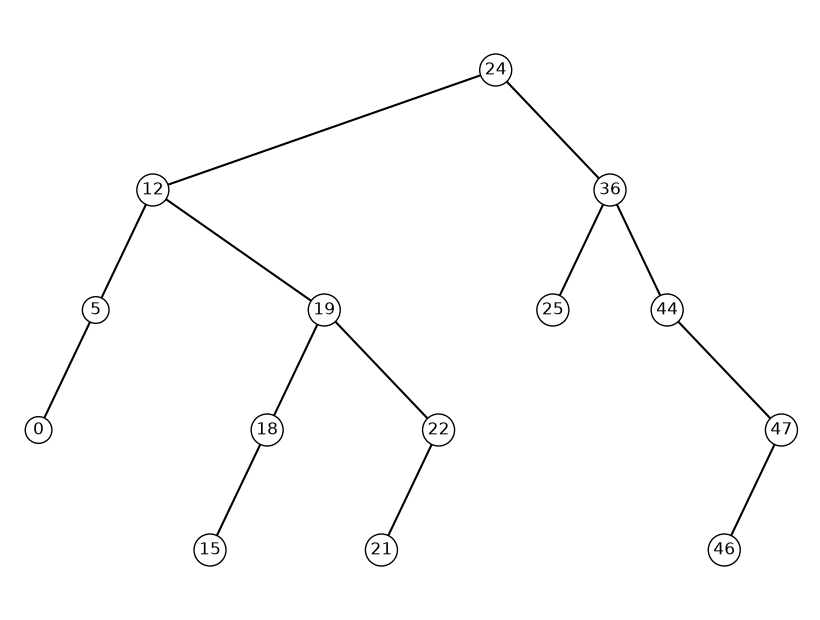

In [6]:
#@title Exercice 7.1

# Il faut faire fonctionner l'insertion des éléments suivants:
un_arbre = ABF()
insertions = [24, 12, 5, 36, 19, 22, 21, 18, 15, 44, 47, 46, 25, 0]
for valeur in insertions:
    un_arbre.inserer(valeur)
dessiner_arbre(un_arbre)


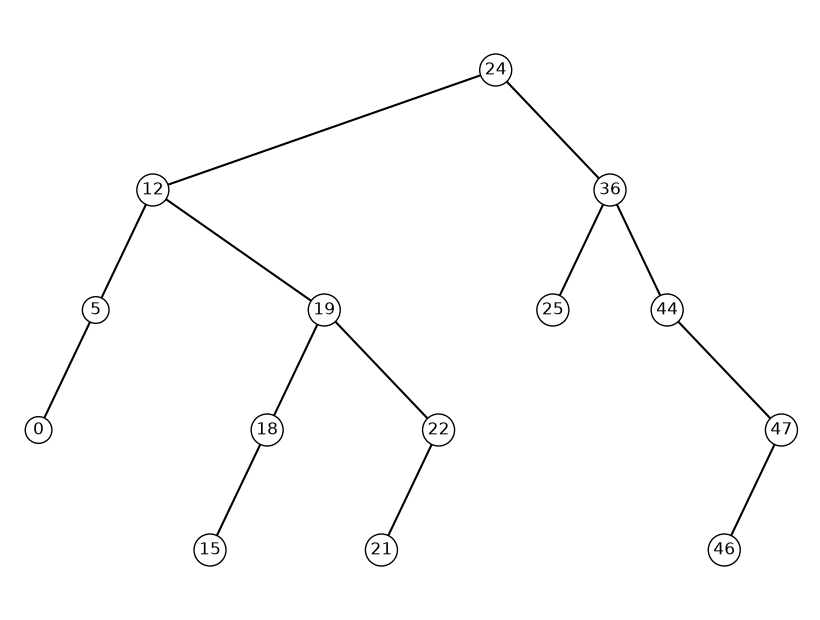

In [7]:
#@title Exercice 7.2

# Même ordre d'insertion qu'à l'exercice 7.1
un_arbre_recursif = ABF()
for valeur in insertions:
    un_arbre_recursif.inserer_recursif(valeur)
dessiner_arbre(un_arbre_recursif)


In [ ]:
#@title Exercice 7.3

for valeur in un_arbre:
    print(valeur, end=" ")
print()


0 5 12 15 18 19 21 22 24 25 36 44 46 47 

In [7]:
#@title Exercice 7.4

# À partir de l'arbre de l'exercice 7.1, faites ces recherches
print(12 in un_arbre)    # Nœuds visités : 24, 12
print(21 in un_arbre)    # Nœuds visités : 24, 12, 19, 22, 21
print(23 in un_arbre)    # Nœuds visités : 24, 12, 19, 22
print(50 in un_arbre)    # Nœuds visités : 24, 36, 44, 47
print(28 in un_arbre)    # Nœuds visités : 24, 36, 25


True
True
False
False
False


Arbre initial: 


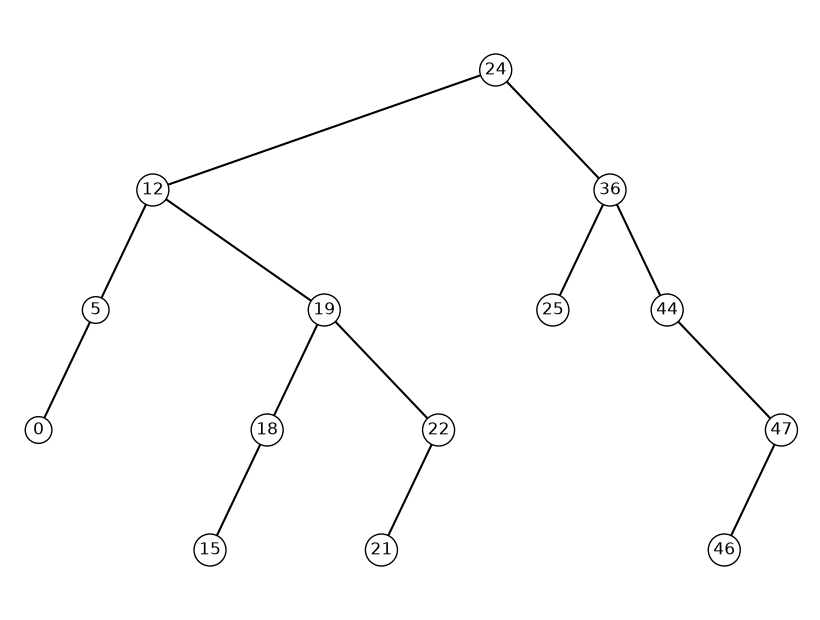

Suppression de 44


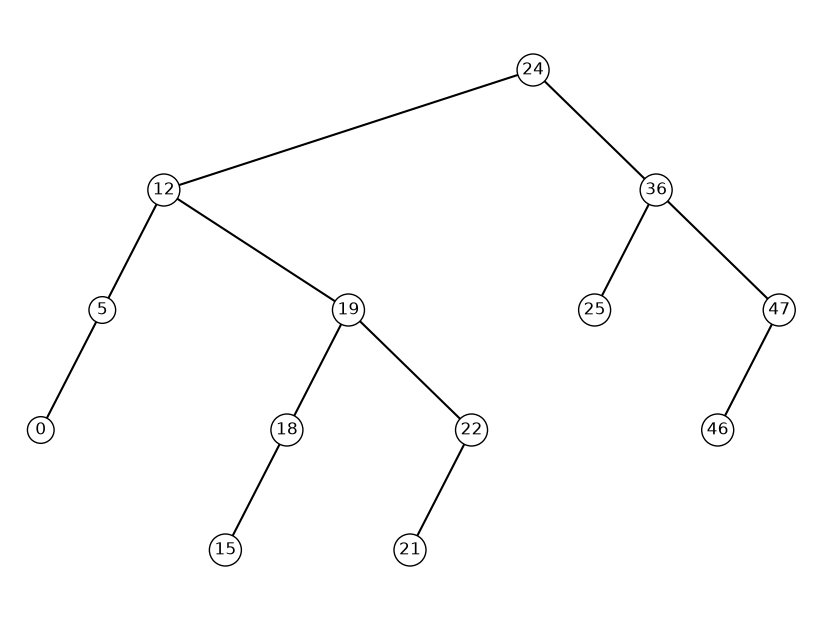

Suppression de 19


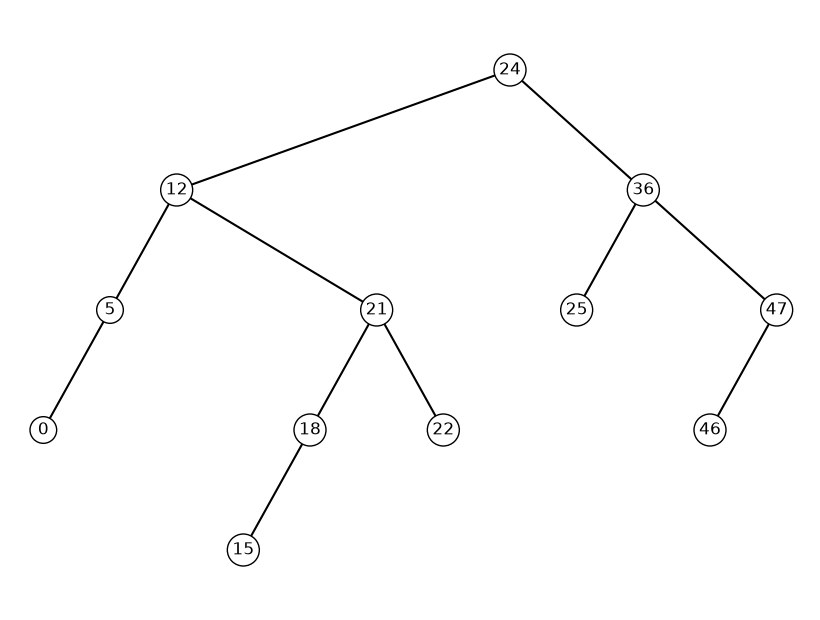

Suppression de 12


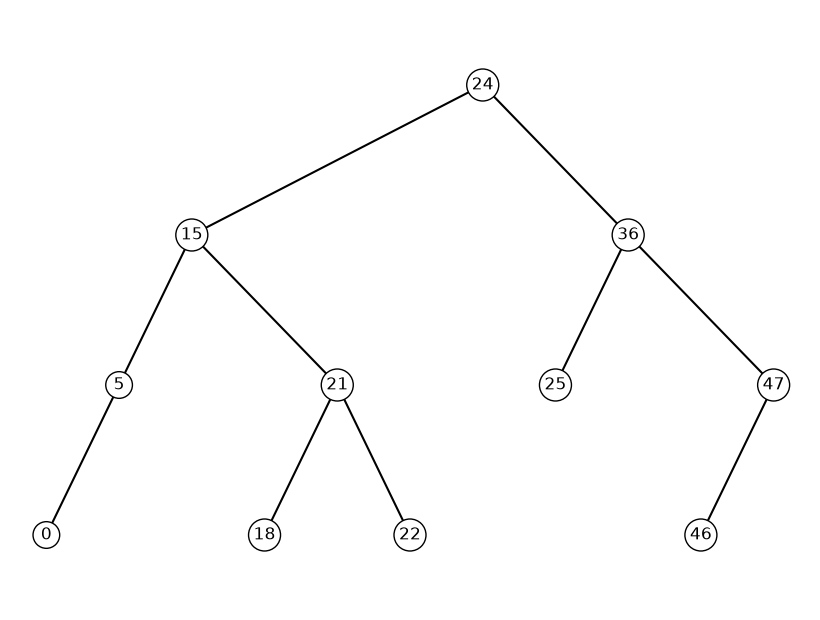

Suppression de 24


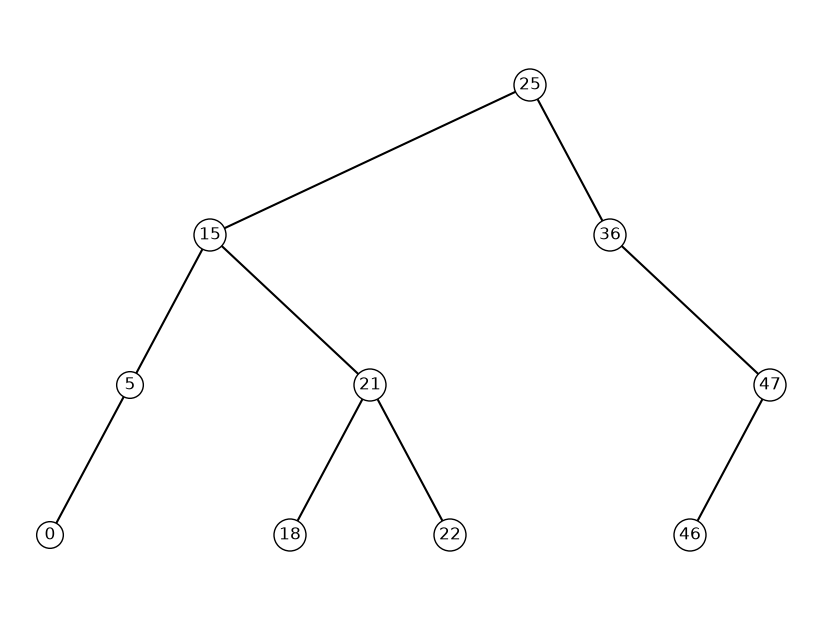

Suppression de 0


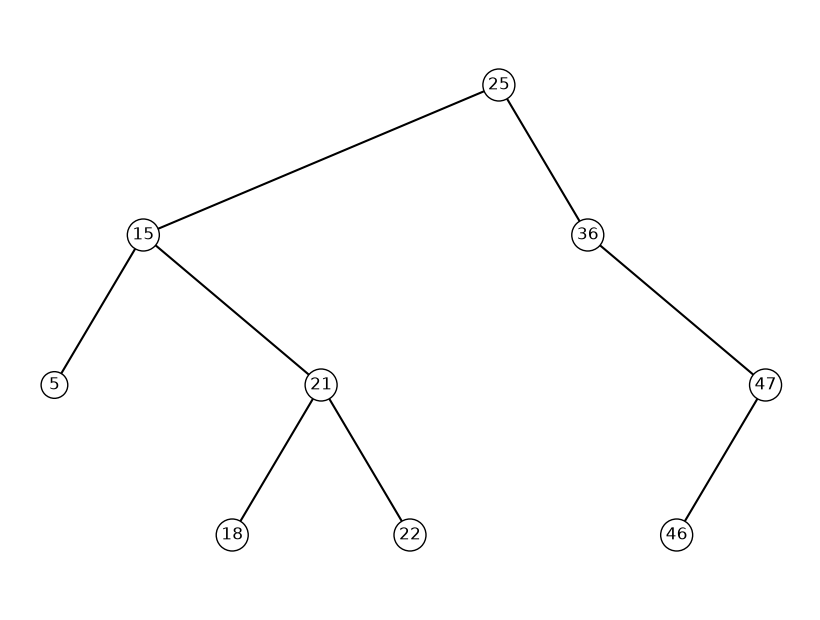

Suppression de 58


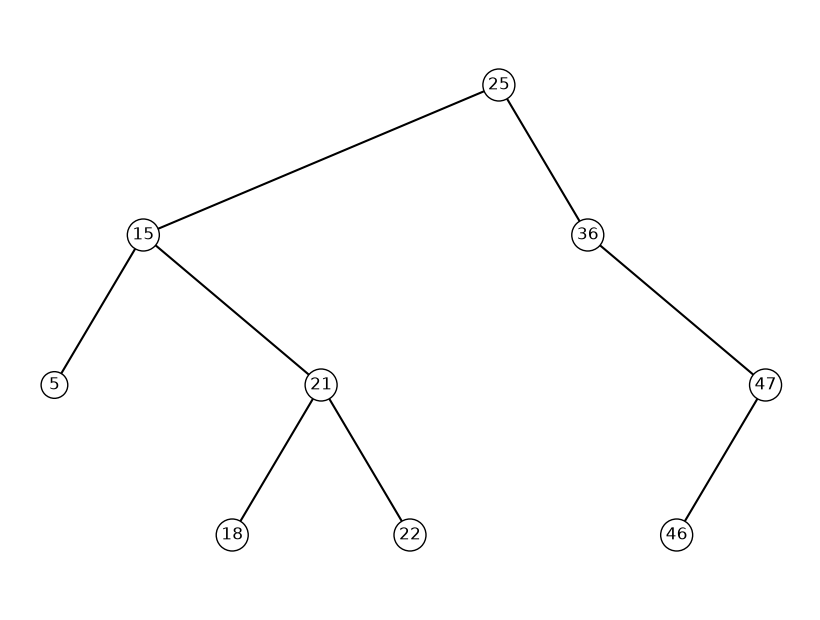

In [8]:
#@title Exercice 7.5

suppressions = [44, 19, 12, 24, 0, 58]

print("Arbre initial: ")
dessiner_arbre(un_arbre)
for valeur in suppressions:
    un_arbre.supprimer(valeur)
    print("Suppression de", valeur)
    dessiner_arbre(un_arbre)



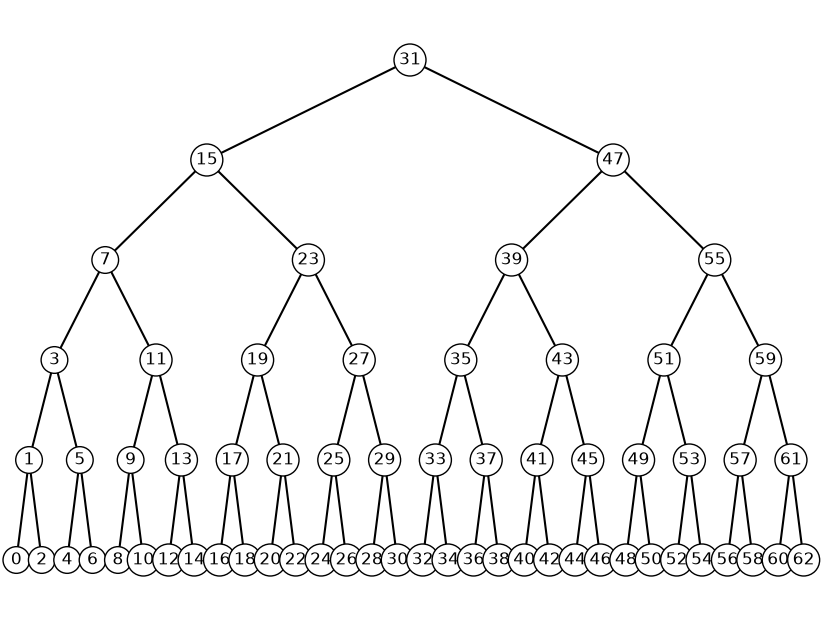

In [9]:
#@title Exercice 7.7

un_arbre = ABF()
for i in range(0, 63):
    un_arbre.inserer(i)

un_arbre.equilibrer()
dessiner_arbre(un_arbre)


In [10]:
#@title Exercice 7.8

ensemble = SortedSet()
insertions = [13, 5, 17, 8, 9, 14, 20, 16, 3, 2, 24, 7, 3, 17]
suppressions = [13, 5, 13, 17]

for valeur in insertions:
    ensemble.add(valeur)

for valeur in suppressions:
    ensemble.discard(valeur)

for valeur in ensemble:
    print(valeur, end= " ")
print()

2 3 7 8 9 14 16 20 24 
